
Training with optimizer: SGD
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6904 - loss: 1.0030 - val_accuracy: 0.9193 - val_loss: 0.2734
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9206 - loss: 0.2581 - val_accuracy: 0.9448 - val_loss: 0.1840
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9491 - loss: 0.1672 - val_accuracy: 0.9683 - val_loss: 0.1091
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9604 - loss: 0.1271 - val_accuracy: 0.9747 - val_loss: 0.0873
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9682 - loss: 0.1044 - val_accuracy: 0.9805 - val_loss: 0.0730

Training with optimizer: SGD+Momentum
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9079 - loss: 0.2968 - val_accuracy: 0.9795 - val_loss: 0.0723
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9782 - loss: 0.0688 - val_accuracy: 0.9820 - val_loss: 0.0629
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 

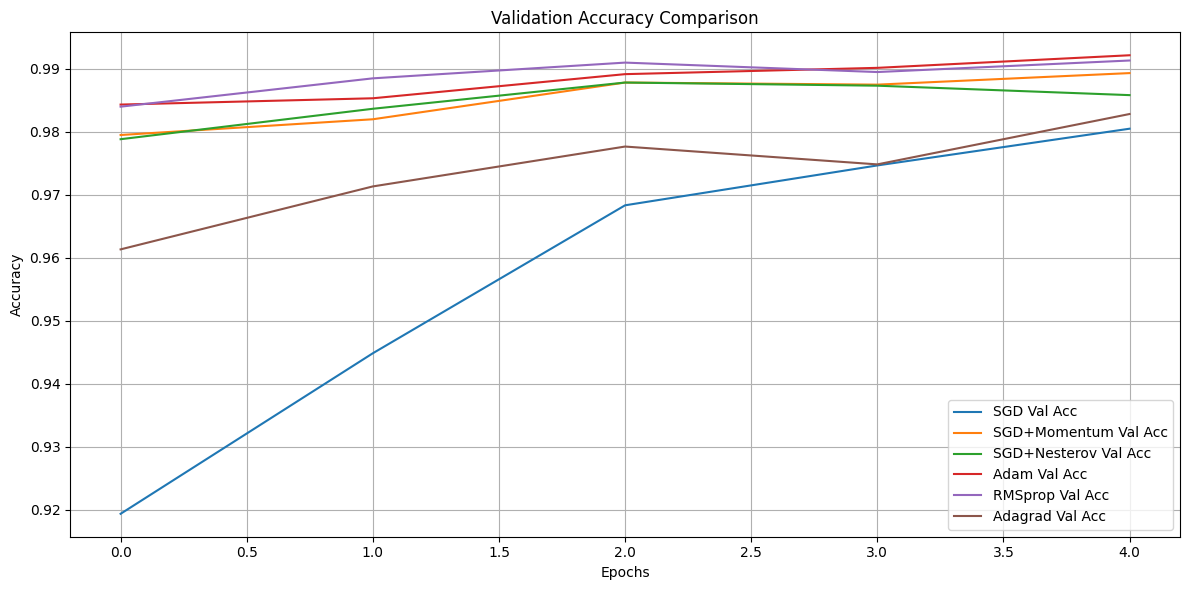

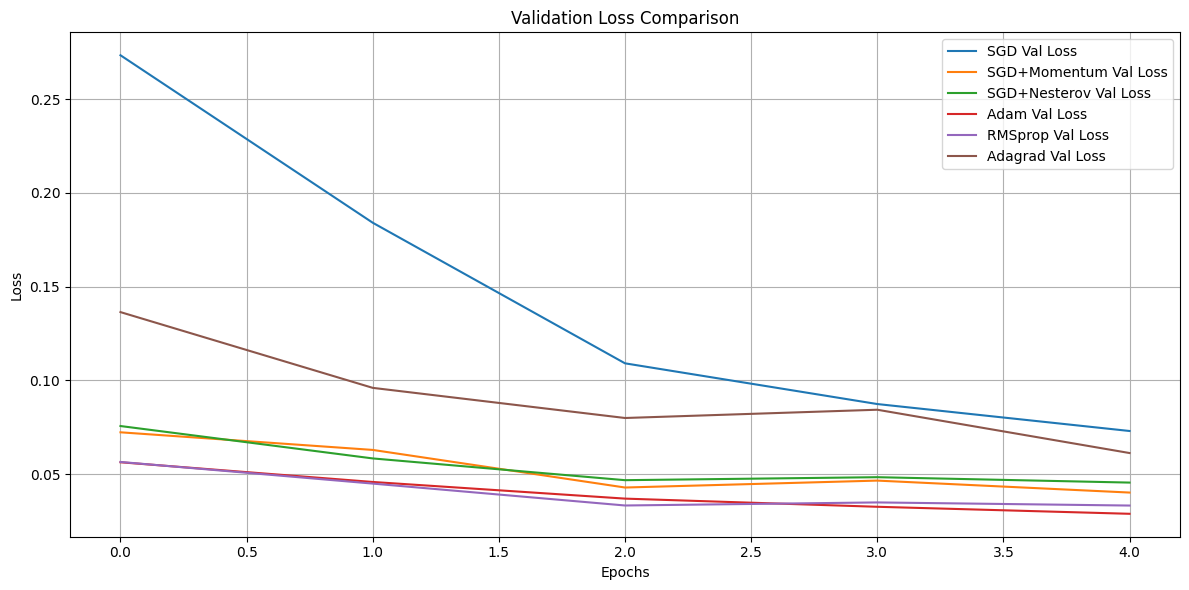


Evaluating optimizer: SGD
SGD Test Accuracy: 97.49%

Evaluating optimizer: SGD+Momentum
SGD+Momentum Test Accuracy: 98.92%

Evaluating optimizer: SGD+Nesterov
SGD+Nesterov Test Accuracy: 99.00%

Evaluating optimizer: Adam
Adam Test Accuracy: 98.80%

Evaluating optimizer: RMSprop


In [ ]:

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models, optimizers
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

train_images = train_images.reshape(-1, 28, 28, 1)
test_images = test_images.reshape(-1, 28, 28, 1)

train_labels = to_categorical(train_labels, 10)
test_labels = to_categorical(test_labels, 10)


def create_model():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    return model


def get_optimizers():
    return {
        "SGD": optimizers.SGD(learning_rate=0.01),
        "SGD+Momentum": optimizers.SGD(
            learning_rate=0.01, momentum=0.9
        ),
        "SGD+Nesterov": optimizers.SGD(
            learning_rate=0.01, momentum=0.9, nesterov=True
        ),
        "Adam": optimizers.Adam(learning_rate=0.001),
        "RMSprop": optimizers.RMSprop(learning_rate=0.001),
        "Adagrad": optimizers.Adagrad(learning_rate=0.01)
    }


histories = {}

for name, optimizer in get_optimizers().items():
    print(f"\nTraining with optimizer: {name}")

    model = create_model()

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_images,
        train_labels,
        epochs=5,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    histories[name] = history


plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=f"{name} Val Acc"
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_loss"],
        label=f"{name} Val Loss"
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


test_accuracies = {}

for name, optimizer in get_optimizers().items():
    print(f"\nEvaluating optimizer: {name}")

    model = create_model()

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_images,
        train_labels,
        epochs=5,
        batch_size=64,
        verbose=0
    )

    test_loss, test_acc = model.evaluate(
        test_images,
        test_labels,
        verbose=0
    )

    test_accuracies[name] = test_acc * 100

    print(f"{name} Test Accuracy: {test_acc * 100:.2f}%")


plt.figure(figsize=(10, 5))
plt.bar(test_accuracies.keys(), test_accuracies.values())
plt.title("Test Accuracy Comparison of Optimizers")
plt.xlabel("Optimizer")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()
